# Solver de cubo mágico 3×3

## Preparação e funções importadas de `cubo.py`

In [1]:
import numpy as np

from cubo import (
    ORDEM_FACES,
    coordenadas_U,
    coordenadas_L,
    coordenadas_F,
    coordenadas_R,
    coordenadas_B,
    coordenadas_D,
    print_cubo,
    plotar_cubo,
    girar_cubo,
    gerar_mapa_movimento,
    mapas_movimentos,
)


## Estado do cubo: vetor de 54 adesivos

Criação do estado resolvido e inspeção da ordem das faces `[U, L, F, R, B, D]`.


In [3]:
# Construindo o cubo magico
possiveis_cores = ['W','G','R','B','O','Y']
cubo_resolvido = np.repeat(possiveis_cores, 9)
print(cubo_resolvido)
print_cubo(cubo_resolvido)
print('\n\n')

cubo_teste = np.arange(54)
print_cubo(cubo_teste)
print('\n\n')

for face, inicio in zip("ULFRBD", range(0, 54, 9)):
    print(face, cubo_resolvido[inicio:inicio + 9])


['W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'G' 'G' 'G' 'G' 'G' 'G' 'G' 'G' 'G'
 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B'
 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']
       W W W
       W W W
       W W W

G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y



       0 1 2
       3 4 5
       6 7 8

9 10 11  18 19 20  27 28 29  36 37 38
12 13 14  21 22 23  30 31 32  39 40 41
15 16 17  24 25 26  33 34 35  42 43 44

       45 46 47
       48 49 50
       51 52 53



U ['W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W']
L ['G' 'G' 'G' 'G' 'G' 'G' 'G' 'G' 'G']
F ['R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R']
R ['B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B']
B ['O' 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'O']
D ['Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']


## Primeiro experimento: movimento U manual

Este bloco preserva o mapa escrito manualmente e o teste de aplicar U quatro vezes.


In [4]:
# Movimento U escrito manualmente para comparar com o mapa geométrico.
movimento_U = np.arange(54)
movimento_U[9], movimento_U[10], movimento_U[11] = 18, 19, 20
movimento_U[18], movimento_U[19], movimento_U[20] = 27, 28, 29
movimento_U[27], movimento_U[28], movimento_U[29] = 36, 37, 38
movimento_U[36], movimento_U[37], movimento_U[38] = 9, 10, 11
movimento_U[0], movimento_U[1], movimento_U[2] = 6, 3, 0
movimento_U[3], movimento_U[4], movimento_U[5] = 7, 4, 1
movimento_U[6], movimento_U[7], movimento_U[8] = 8, 5, 2

cubo_atual = cubo_resolvido.copy()
for giro in range(1, 5):
    cubo_atual = girar_cubo(cubo_atual, movimento_U)
    print(f"--- Giro {giro} ---")
    print_cubo(cubo_atual)


--- Giro 1 ---
       W W W
       W W W
       W W W

R R R  B B B  O O O  G G G
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--- Giro 2 ---
       W W W
       W W W
       W W W

B B B  O O O  G G G  R R R
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--- Giro 3 ---
       W W W
       W W W
       W W W

O O O  G G G  R R R  B B B
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--- Giro 4 ---
       W W W
       W W W
       W W W

G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y


## Coordenadas das faces em R³

Experimentos com as coordenadas e rotações das faces U e F, seguidos das coordenadas das outras faces.


In [5]:
# Rotação U aplicada às coordenadas de uma face vizinha.
move_U = np.array([
    [0,  1, 0],
    [-1, 0, 0],
    [0,  0, 1]
])

coordenadas_U_giradas = coordenadas_U @ move_U.T
print(coordenadas_U)
print("Após U:")
print(coordenadas_U_giradas)


[[[-1  1  1]
  [-1  0  1]
  [-1 -1  1]]

 [[ 0  1  1]
  [ 0  0  1]
  [ 0 -1  1]]

 [[ 1  1  1]
  [ 1  0  1]
  [ 1 -1  1]]]
Após U:
[[[ 1  1  1]
  [ 0  1  1]
  [-1  1  1]]

 [[ 1  0  1]
  [ 0  0  1]
  [-1  0  1]]

 [[ 1 -1  1]
  [ 0 -1  1]
  [-1 -1  1]]]


In [6]:
# Rotação em torno do eixo x aplicada às coordenadas da face F.
move_U_front = np.array([
    [1,  0,  0],
    [0,  0,  1],
    [0, -1,  0]
])

coordenadas_F_giradas = coordenadas_F @ move_U_front.T
print(coordenadas_F)
print("Após a rotação:")
print(coordenadas_F_giradas)


[[[ 1  1  1]
  [ 1  0  1]
  [ 1 -1  1]]

 [[ 1  1  0]
  [ 1  0  0]
  [ 1 -1  0]]

 [[ 1  1 -1]
  [ 1  0 -1]
  [ 1 -1 -1]]]
Após F:
[[[ 1  1 -1]
  [ 1  1  0]
  [ 1  1  1]]

 [[ 1  0 -1]
  [ 1  0  0]
  [ 1  0  1]]

 [[ 1 -1 -1]
  [ 1 -1  0]
  [ 1 -1  1]]]


In [7]:
# As seis grades geométricas importadas do módulo.
for face, grade in zip(ORDEM_FACES, (
    coordenadas_U, coordenadas_L, coordenadas_F,
    coordenadas_R, coordenadas_B, coordenadas_D,
)):
    print(f"{face}:\n", grade)


L:
 [[[-1  1  1]
  [ 0  1  1]
  [ 1  1  1]]

 [[-1  1  0]
  [ 0  1  0]
  [ 1  1  0]]

 [[-1  1 -1]
  [ 0  1 -1]
  [ 1  1 -1]]]
R:
 [[[ 1 -1  1]
  [ 0 -1  1]
  [-1 -1  1]]

 [[ 1 -1  0]
  [ 0 -1  0]
  [-1 -1  0]]

 [[ 1 -1 -1]
  [ 0 -1 -1]
  [-1 -1 -1]]]
B:
 [[[-1 -1  1]
  [-1  0  1]
  [-1  1  1]]

 [[-1 -1  0]
  [-1  0  0]
  [-1  1  0]]

 [[-1 -1 -1]
  [-1  0 -1]
  [-1  1 -1]]]
D:
 [[[ 1  1 -1]
  [ 1  0 -1]
  [ 1 -1 -1]]

 [[ 0  1 -1]
  [ 0  0 -1]
  [ 0 -1 -1]]

 [[-1  1 -1]
  [-1  0 -1]
  [-1 -1 -1]]]


## Geometria completa e plot do cubo

As grades, direções e normais agora são importadas de `cubo.py`; este bloco mantém os plots.


<Axes3D: >

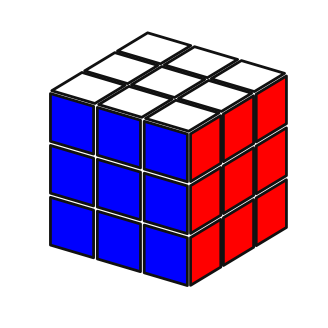

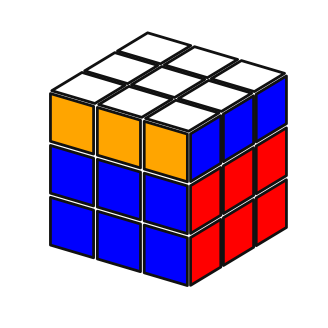

In [8]:
# Mantém a visualização do cubo resolvido e após o movimento U manual.
plotar_cubo(cubo_resolvido)
plotar_cubo(girar_cubo(cubo_resolvido, movimento_U))


## Gerar movimentos a partir da geometria

A função importada de `cubo.py` recebe o nome da face e constrói o mapa de permutação correspondente.


## Aplicar e explorar os movimentos gerados

Experimentos atuais com U, F e F². Os códigos e testes existentes foram mantidos.


       W W W
       W W W
       W W W

R R R  B B B  O O O  G G G
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
       W W W
       W W W
       G G G

G G Y  R R R  W B B  O O O
G G Y  R R R  W B B  O O O
G G Y  R R R  W B B  O O O

       B B B
       Y Y Y
       Y Y Y
       W W W
       W W W
       Y Y Y

G G B  R R R  G B B  O O O
G G B  R R R  G B B  O O O
G G B  R R R  G B B  O O O

       W W W
       Y Y Y
       Y Y Y


<Axes3D: >

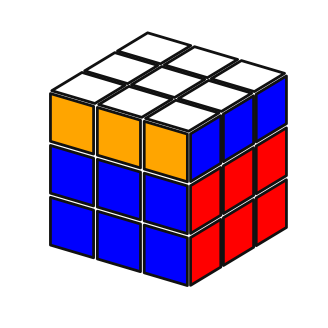

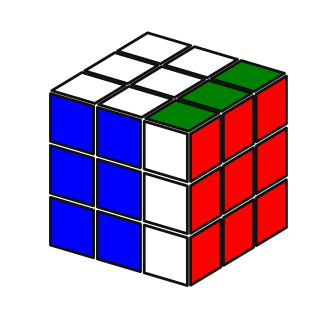

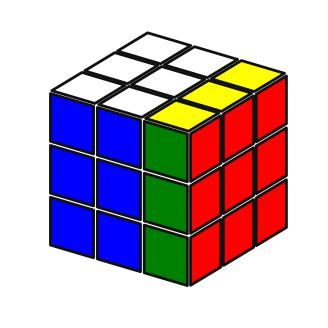

In [10]:
mapa_U_geometrico = gerar_mapa_movimento("U")

cubo_depois_de_U = girar_cubo(cubo_resolvido, mapa_U_geometrico)

print_cubo(cubo_depois_de_U)
plotar_cubo(cubo_depois_de_U)

mapa_F_geometrico = gerar_mapa_movimento("F")

cubo_depois_de_F = girar_cubo(cubo_resolvido, mapa_F_geometrico)

print_cubo(cubo_depois_de_F)
plotar_cubo(cubo_depois_de_F)


cubo_depois_de_F = girar_cubo(cubo_depois_de_F, mapa_F_geometrico)

print_cubo(cubo_depois_de_F)
plotar_cubo(cubo_depois_de_F)

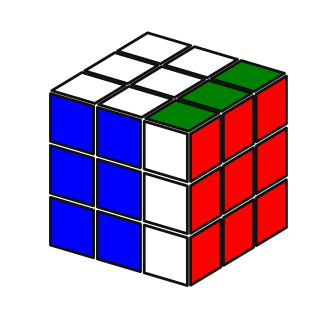

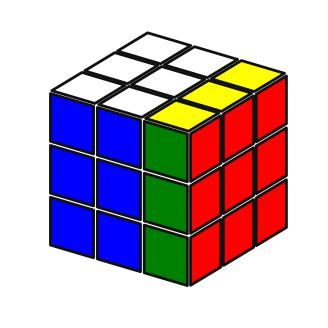

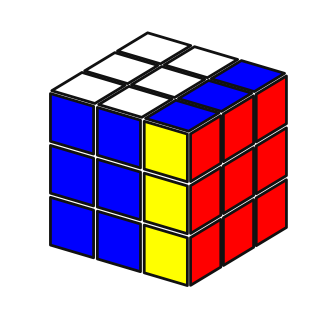

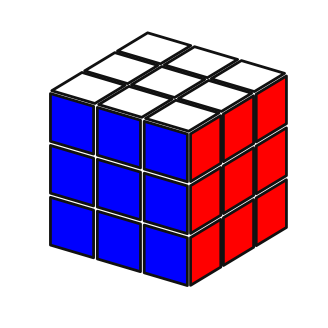

In [11]:
cubo_depois_de_Fv2 = girar_cubo(cubo_resolvido, mapa_F_geometrico)
plotar_cubo(cubo_depois_de_Fv2)
for i in range(0,3):
    cubo_depois_de_Fv2 = girar_cubo(cubo_depois_de_Fv2, mapa_F_geometrico)
    plotar_cubo(cubo_depois_de_Fv2)

In [12]:
mapa_U_geometrico = gerar_mapa_movimento("U")
print(np.array_equal(mapa_U_geometrico, movimento_U))


True


In [13]:
# Os 18 mapas (horários, anti-horários e giros de 180°) vêm de cubo.py.
faces = ORDEM_FACES


In [14]:
cubo_depois_de_RA = girar_cubo(cubo_atual, mapas_movimentos["R'"])
cubo_depois_de_U2 = girar_cubo(cubo_atual, mapas_movimentos["U2"])
print_cubo(cubo_depois_de_RA)
print_cubo(cubo_depois_de_U2)

       W W O
       W W O
       W W O

G G G  R R W  B B B  Y O O
G G G  R R W  B B B  Y O O
G G G  R R W  B B B  Y O O

       Y Y R
       Y Y R
       Y Y R
       W W W
       W W W
       W W W

B B B  O O O  G G G  R R R
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y


In [15]:
ids = np.arange(54)

for face in faces:
    mapa = mapas_movimentos[face]
    inverso = mapas_movimentos[face + "'"]
    giro_duplo = mapas_movimentos[face + "2"]

    assert np.array_equal(girar_cubo(girar_cubo(ids, mapa), inverso), ids)
    assert np.array_equal(girar_cubo(girar_cubo(ids, mapa), mapa), giro_duplo)


In [16]:
ids = np.arange(54)
resultado = girar_cubo(ids, mapas_movimentos["R'"])

unicos = len(np.unique(resultado)) == len(ids)
print(unicos)


True
